# A rock factor that uses nothing from the target site, and how much of the classical score was borrowed

**Question:** Can the rock factor be predicted from the modulus of the other sites, and what does it cost?

**Level 4: Beyond the state of the art** · Needs: 02-classical-prediction/02-the-rock-factor, 02-classical-prediction/03-the-published-hold-out-tables · Reading time: about 35 minutes

## Objectives

The classical predictor of the previous notebooks reads a rock factor that was recovered from the published predictions for the very site it is scored on. Held out by site, that is knowledge of the held-out site, which a learned predictor is never given. This notebook measures how much of the classical score that knowledge buys, by replacing the site constant with a factor predicted from the rock's Young modulus using the other sites only (claim BS-4).

By the end you will have:

- tabulated the nine recovered factors against the site moduli, fitted the log-linear relation between them and read its slope and correlation;
- predicted the factor of every site from the other nine, and compared it with the factor recovered from the paper;
- scored the site-constant predictor, the transfer predictor and a constant under leave-one-site-out, with intervals that resample sites;
- read, site by site, where replacing the factor helps and where it costs.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, sets the plotting style and defines `show_table`, a four-line helper that renders rows as a Markdown table because the notebook environment has no `pandas`.

In [1]:
# Imports, the pinned versions, the plotting style and one helper that renders a table
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts and their rock moduli | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The per-site rock factors recovered from the printed predictions | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 2012 column) | numeric facts reused with citation | `bf.derive_site_rock_factors` and `bf.SITE_ROCK_FACTOR` inside the wheel |

No file under `data/` is read: the leave-one-site-out runs are executed here, with the engine.

## Method

The transfer predictor fits one straight line in logarithms through the sites,

```
ln A = a + b * ln E
```

with one point per site (the site's recovered factor against its mean modulus), so a 22-blast quarry and a six-blast mine weigh the same. The factor of a blast is then `exp(a + b ln E)` from its own modulus, which an engineer has before the first blast at a new mine. The relation is a calibration of this engine, not a published equation. Under leave-one-site-out, the line is refitted without the held-out site on every fold, so the held-out site contributes nothing to its own factor. The score of a predictor is the variance explained about the identity line; its interval comes from a bootstrap that resamples sites, not blasts, because rows of one campaign are not independent draws (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

### Step 1: the factors and the moduli of the nine sites

The cell asks the engine for the recovered factor of each site, `derive_site_rock_factors("kuzram_2012")`, and computes the mean rock modulus of each site from the corpus. The table orders the sites by modulus, so that any relation between the two columns can be read down the page.

In [2]:
# The recovered factor and the mean modulus of each site, from the engine's derivation
train = bf.load_training_corpus()
derived = bf.derive_site_rock_factors("kuzram_2012")
sites = sorted(derived)
modulus = {site: float(np.mean([b.E_GPa for b in train if b.site == site])) for site in sites}
rows = []
for site in sorted(sites, key=modulus.get):
    rows.append((site, f"{modulus[site]:.2f}", f"{derived[site][0]:.2f}", derived[site][1]))
header = ["site", "mean modulus E (GPa)", "recovered rock factor A",
          "blasts used"]
show_table(header, rows)

| site | mean modulus E (GPa) | recovered rock factor A | blasts used |
|:---|---:|---:|---:|
| Dongri-Buzurg | 9.57 | 3.68 | 1 |
| Soma | 13.25 | 6.24 | 1 |
| Ozmert | 15.00 | 6.44 | 2 |
| Akdaglar | 16.90 | 6.72 | 2 |
| Mrica | 32.00 | 6.32 | 1 |
| Reocin | 45.00 | 12.14 | 1 |
| Reocin-UG | 45.00 | 11.19 | 1 |
| Murgul | 50.00 | 9.23 | 2 |
| Enusa | 60.00 | 10.97 | 1 |

Read down the table: the factor rises with the modulus, from 3.68 at 9.57 GPa (Dongri-Buzurg) to 10.97 at 60 GPa (Enusa), but not smoothly. Mrica, at 32 GPa, has a factor of 6.32, below Akdaglar's 6.72 at 16.9 GPa, and Reocin and Reocin-UG share a modulus of 45 GPa with factors of 12.14 and 11.19. So the relation is a trend with scatter, which a line can capture only roughly. The table fixes the nine pairs that the next cell fits; it says nothing about their causal link.

In [3]:
# Fit the log-linear line through the nine sites and measure how tight the relation is
transfer = bf.KuznetsovTransfer().fit(train)
log_e = np.log([modulus[site] for site in transfer.fit_sites])
log_a = np.log([derived[site][0] for site in transfer.fit_sites])
correlation = np.corrcoef(log_e, log_a)[0, 1]
rows = [("intercept a", f"{transfer.intercept:.4f}"), ("slope b", f"{transfer.slope:.4f}"),
        ("sites in the fit", len(transfer.fit_sites)), ("correlation of ln A with ln E", f"{correlation:.3f}")]
show_table(["quantity", "value"], rows)

| quantity | value |
|:---|---:|
| intercept a | 0.3841 |
| slope b | 0.5029 |
| sites in the fit | 9 |
| correlation of ln A with ln E | 0.891 |

The line has an intercept of 0.3841 and a slope of 0.5029 over the nine sites, so the factor grows roughly with the square root of the modulus, and the correlation of the logarithms is 0.891. A strong correlation over nine points is encouraging and still weak evidence: nine points constrain a line, not a law. The next cell draws the nine points and the line.

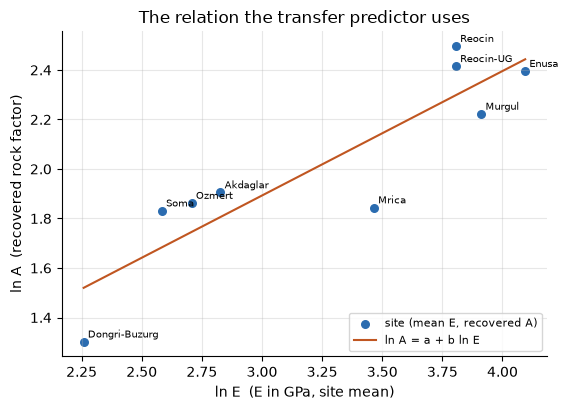

In [4]:
# ln A against ln E for the nine sites, with the fitted line
fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.scatter(log_e, log_a, s=30, color="#2b6cb0", label="site (mean E, recovered A)")
for site, x, y in zip(transfer.fit_sites, log_e, log_a):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
grid = np.linspace(log_e.min(), log_e.max(), 20)
ax.plot(grid, transfer.intercept + transfer.slope * grid, color="#c05621", label="ln A = a + b ln E")
ax.set_xlabel("ln E  (E in GPa, site mean)")
ax.set_ylabel("ln A  (recovered rock factor)")
ax.set_title("The relation the transfer predictor uses")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

The nine sites lie close to the orange line, with the largest departures at Mrica and at Dongri-Buzurg, both below it, which means that the line overstates their factors, while Reocin and Reocin-UG sit above it at the same abscissa. The figure shows that a single modulus carries a real part of the information about the rock factor. It does not show that the line would hold at a tenth site, since every point here also helped to fit it; that is what the leave-one-site-out runs of the next steps test.

## State of the art

- The two source papers (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3) state that the rock factor was estimated for each blast and print no value. The factors recovered from their predictions behave as a per-site constant (the previous notebook: a spread of a few percent inside a site).
- Any evaluation of the classical equation that uses those factors on the same site therefore gives the equation a number tuned to the site, and the SDD's research basis notes that the published learned-predictor studies do not hold out a whole mine. A held-out-site score of such a predictor cannot separate the equation's skill from the factor's origin.
- Resampling the right unit matters: cross-validation that ignores dependence in the data can seriously underestimate prediction error (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Beyond the state of the art

**Claim BS-4, a rock factor that uses nothing from the target site.** The transfer predictor replaces the site constant with a factor predicted from the modulus of the other sites. Its premise is testable: under leave-one-site-out, what does the classical score become when the held-out site's own factor is taken away, and by how much does the answer move? The three steps below hold out each campaign in turn, compare the predicted factor with the recovered one, score three predictors with intervals that resample sites, and read the cost site by site.

### Step 2: leave one site out, and predict its factor from the others

For each of the ten campaigns the cell holds the whole campaign out, refits the transfer line on the other nine, predicts the held-out campaign with three predictors (the site-constant classical predictor, the transfer predictor and the null model that predicts the mean of the other campaigns) and records the factor that the transfer line gave it. Miami has no scale, so both classical predictors abstain there; its factor is predicted anyway, and has nothing to be compared with. The table sets each predicted factor beside the recovered one.

In [5]:
# Hold out each campaign in turn, refit on the other nine, and keep what each classical predictor says about it
tested, predictions, predicted_factor = [], {"kuznetsov": [], "kuznetsov-transfer": [], "null": []}, {}
for split in bf.leave_one_site_out(train):
    site = split.detail["held_out_site"]
    refit = bf.KuznetsovTransfer().fit(split.train)
    predictions["kuznetsov"] += bf.Kuznetsov().fit(split.train).predict(split.test)
    predictions["kuznetsov-transfer"] += refit.predict(split.test)
    predictions["null"] += bf.NullModel().fit(split.train).predict(split.test)
    tested += list(split.test)
    predicted_factor[site] = refit.rock_factor_for(float(np.mean([b.E_GPa for b in split.test])))
rows = []
for site, factor in predicted_factor.items():
    recovered = bf.SITE_ROCK_FACTOR.get(site)
    error = f"{factor / recovered - 1:+.1%}" if recovered else "-"
    rows.append((site, f"{recovered:.2f}" if recovered else "-", f"{factor:.2f}", error))
header = ["held-out site", "recovered A", "predicted A from the other sites",
          "relative error"]
show_table(header, rows)

| held-out site | recovered A | predicted A from the other sites | relative error |
|:---|---:|---:|---:|
| Akdaglar | 6.72 | 5.97 | -11.2% |
| Dongri-Buzurg | 3.68 | 5.25 | +42.6% |
| Enusa | 10.97 | 11.74 | +7.0% |
| Miami | - | 4.67 | - |
| Mrica | 6.32 | 8.72 | +38.0% |
| Murgul | 9.23 | 10.89 | +18.0% |
| Ozmert | 6.44 | 5.57 | -13.5% |
| Reocin | 12.14 | 9.51 | -21.6% |
| Reocin-UG | 11.19 | 9.69 | -13.4% |
| Soma | 6.24 | 5.14 | -17.6% |

Predicted from the other sites only, the factor lands within 7.0 percent of the recovered one at Enusa and within 11.2 percent at Akdaglar, and misses by 42.6 percent at Dongri-Buzurg, the site with the lowest modulus, which the line must extrapolate to, and by 38.0 percent at Mrica. The errors have both signs: the line overshoots Dongri-Buzurg, Mrica, Murgul and Enusa and undershoots the other five. Miami receives 4.67, a value with nothing to check it against. The table lists the errors of each fold; the next cell draws them.

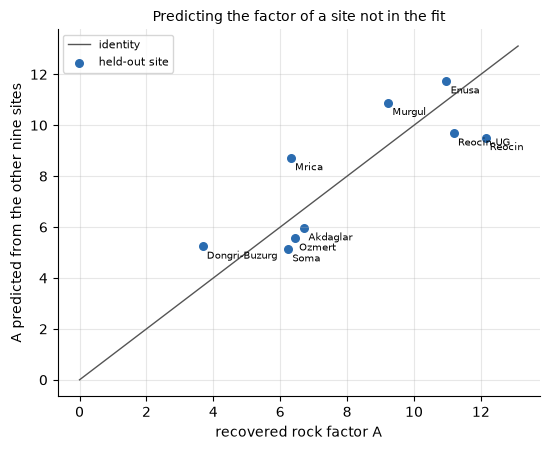

median absolute relative error: 17.6% | largest: 42.6%


In [6]:
# Factor predicted from the other sites against the factor recovered from the paper, one point per held-out site
known = [site for site in predicted_factor if site in bf.SITE_ROCK_FACTOR]
recovered = np.array([bf.SITE_ROCK_FACTOR[s] for s in known])
predicted = np.array([predicted_factor[s] for s in known])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
limit = max(recovered.max(), predicted.max()) * 1.08
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identity")
ax.scatter(recovered, predicted, s=30, color="#2b6cb0", label="held-out site")
for site, x, y in zip(known, recovered, predicted):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("recovered rock factor A")
ax.set_ylabel("A predicted from the other nine sites")
ax.set_title("Predicting the factor of a site not in the fit", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
errors = np.abs(predicted / recovered - 1)
print("median absolute relative error:", f"{np.median(errors):.1%}", "| largest:", f"{errors.max():.1%}")

Each point is one held-out site, with its recovered factor on the horizontal axis and the factor predicted from the other nine on the vertical axis, against the identity line. The points follow the line without hugging it: most sit within a band of about a fifth around it, and two, Dongri-Buzurg and Mrica, sit far above. The median absolute relative error of the nine is 17.6 percent and the largest 42.6 percent. The figure shows what predicting a factor from the modulus costs in the factor itself; it does not translate that cost into fragment size, which is the next step.

### Step 3: score the three predictors with intervals that resample sites

The predictions of Step 2 are pooled over the folds and scored on the 91 blasts that have a known scale (the six Miami blasts are not scored, because the classical predictors abstain on them). The cell computes, for each predictor, the variance explained about the identity line and its 95 percent interval from 2000 bootstrap resamples of whole sites (`unit="site"`), and the RMSE in metres. The null model, which predicts the mean of the other campaigns, is scored on the same rows as the reference.

In [7]:
# Score each predictor on the 91 blasts with a known scale, with a 95 percent interval that resamples sites
scored = {}
rows = []
for name, predicted_all in predictions.items():
    answered = [(b, p) for b, p in zip(tested, predicted_all) if p.x50_m is not None and bf.has_absolute_geometry(b)]
    blasts, preds = [a[0] for a in answered], [a[1] for a in answered]
    point, low, high = bf.bootstrap_interval(blasts, preds, "r2_identity", n_boot=2000, unit="site", seed=0)
    rmse = bf.score(blasts, preds).rmse_m
    scored[name] = (blasts, preds, point, low, high)
    rows.append((name, len(blasts), f"{point:.4f}", f"{low:.3f} to {high:.3f}", f"{rmse:.4f}"))
header = ["predictor", "blasts", "r2 about identity",
          "interval 95 % (sites resampled)", "RMSE (m)"]
show_table(header, rows)
cost = scored["kuznetsov"][2] - scored["kuznetsov-transfer"][2]
print("cost of the transfer in r2 about identity:", f"{cost:.4f}")

| predictor | blasts | r2 about identity | interval 95 % (sites resampled) | RMSE (m) |
|:---|---:|---:|---:|---:|
| kuznetsov | 91 | 0.3112 | -0.966 to 0.686 | 0.1528 |
| kuznetsov-transfer | 91 | 0.2982 | -1.097 to 0.708 | 0.1543 |
| null | 91 | -0.2320 | -1.330 to -0.158 | 0.2044 |

cost of the transfer in r2 about identity: 0.0130


Replacing the site constant barely moves the score. The site-constant predictor explains 0.3112 of the variance and the transfer predictor 0.2982, a difference of 0.0130, and their RMSE is 0.1528 m against 0.1543 m. Both intervals are wide, -0.966 to 0.686 and -1.097 to 0.708, and span zero by a wide margin. The null model scores -0.2320 with an RMSE of 0.2044 m, and its interval, -1.330 to -0.158, overlaps the classical ones. So the classical score does not depend on the site constant, and it is not clearly better than a constant either: nine sites cannot settle it.

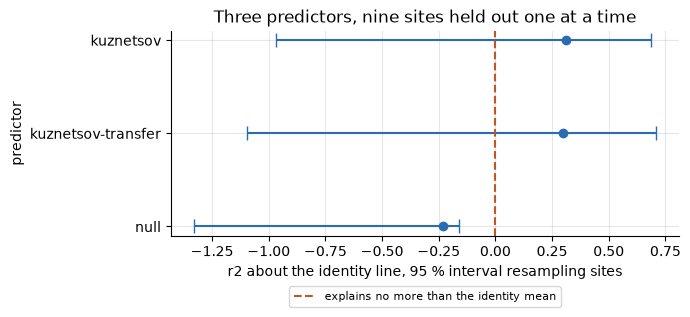

In [8]:
# The three scores with their site-resampled intervals, the zero line marked
names = list(scored)
fig, ax = plt.subplots(figsize=(7, 3.4))
for position, name in enumerate(names):
    point, low, high = scored[name][2:]
    ax.errorbar(point, position, xerr=[[point - low], [high - point]], fmt="o", color="#2b6cb0", capsize=5)
ax.axvline(0, color="#c05621", ls="--", label="explains no more than the identity mean")
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_ylabel("predictor")
ax.set_xlabel("r2 about the identity line, 95 % interval resampling sites")
ax.set_title("Three predictors, nine sites held out one at a time")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout()
plt.show()

Each row is one predictor: the dot is its variance explained about the identity line and the whisker its 95 percent interval from resampling sites, with the dashed line at zero. The two classical predictors have almost the same dot and almost the same whisker, which is the main finding: the site's own factor is not what holds the score up. Their whiskers cross zero and reach the null's, so the figure cannot say that either beats a constant. It also does not compare the two classical predictors directly on the same resamples; the intervals are for each score, not for their difference.

### Step 4: where it helps and where it costs

A pooled score can hide opposite effects. The cell scores each of the two classical predictors separately on each held-out site, by RMSE in metres, and lists the change from the site constant to the transfer predictor. A positive change means that taking the site's own factor away made that site's predictions worse.

In [9]:
# RMSE of the site-constant and the transfer predictor on each held-out site
by_site = {}
for name in ("kuznetsov", "kuznetsov-transfer"):
    blasts, preds = scored[name][:2]
    for site in sorted({b.site for b in blasts}):
        pairs = [(b, p) for b, p in zip(blasts, preds) if b.site == site]
        by_site.setdefault(site, {})[name] = bf.score([b for b, _ in pairs], [p for _, p in pairs]).rmse_m
rows = []
for site, v in by_site.items():
    constant, moved = v["kuznetsov"], v["kuznetsov-transfer"]
    rows.append((site, f"{constant:.3f}", f"{moved:.3f}", f"{moved - constant:+.3f}"))
show_table(["held-out site", "RMSE kuznetsov (m)", "RMSE kuznetsov-transfer (m)", "change (m)"], rows)

| held-out site | RMSE kuznetsov (m) | RMSE kuznetsov-transfer (m) | change (m) |
|:---|---:|---:|---:|
| Akdaglar | 0.054 | 0.057 | +0.003 |
| Dongri-Buzurg | 0.330 | 0.290 | -0.040 |
| Enusa | 0.147 | 0.175 | +0.028 |
| Mrica | 0.111 | 0.213 | +0.102 |
| Murgul | 0.052 | 0.110 | +0.057 |
| Ozmert | 0.061 | 0.061 | +0.000 |
| Reocin | 0.216 | 0.166 | -0.050 |
| Reocin-UG | 0.093 | 0.086 | -0.007 |
| Soma | 0.132 | 0.076 | -0.056 |

The effects are mixed. The transfer predictor is worse at four sites: Mrica by 0.102 m, Murgul by 0.057 m, Enusa by 0.028 m and Akdaglar by 0.003 m, and equal at Ozmert. It is better at four: Soma by 0.056 m, Reocin by 0.050 m, Dongri-Buzurg by 0.040 m and Reocin-UG by 0.007 m. At the site of the largest factor error, Dongri-Buzurg, the factor was 42.6 percent too high and the RMSE still fell, because the site-constant predictor was already off by 0.330 m. So the pooled result of a few thousandths of a metre is a balance of larger effects with both signs, not an absence of effect.

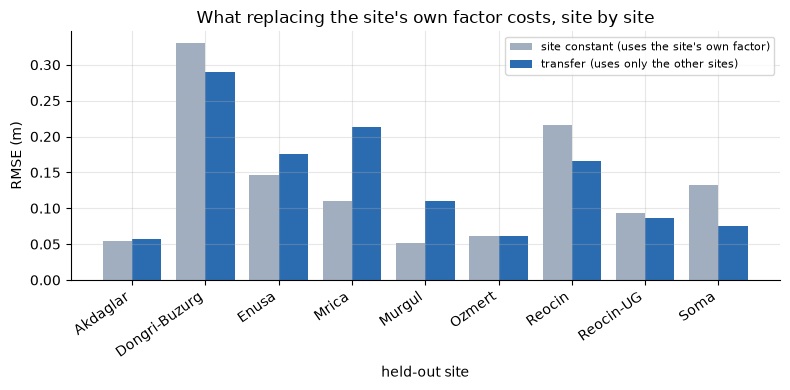

In [10]:
# Per-site RMSE of the two classical predictors, side by side
names = list(by_site)
positions = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
constant_label = "site constant (uses the site's own factor)"
transfer_label = "transfer (uses only the other sites)"
constant = [by_site[s]["kuznetsov"] for s in names]
moved = [by_site[s]["kuznetsov-transfer"] for s in names]
ax.bar(positions - 0.2, constant, width=0.4, color="#a0aec0", label=constant_label)
ax.bar(positions + 0.2, moved, width=0.4, color="#2b6cb0", label=transfer_label)
ax.set_xticks(positions, names, rotation=35, ha="right")
ax.set_xlabel("held-out site")
ax.set_ylabel("RMSE (m)")
ax.set_title("What replacing the site's own factor costs, site by site")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

For each held-out site the grey bar is the RMSE of the predictor that uses the site's own factor and the blue bar that of the predictor that uses only the other sites. Blue is higher at Mrica, Murgul and Enusa, and lower at Dongri-Buzurg, Reocin and Soma; at Akdaglar and Ozmert the bars are equal. The size of the bars also varies by a factor of six between sites, so the large errors at Dongri-Buzurg dominate either way. The figure shows that the cost of the transfer is site-specific; it does not say which sites will be easy at a new mine, which no figure on nine sites can.

## Results

**Answer:** Yes, to within about a fifth. Predicted from the modulus of the other nine sites alone, the rock factor of a held-out site has a median absolute relative error of 17.6 percent and a largest error of 42.6 percent (Dongri-Buzurg), against the factor recovered from the paper. The cost in prediction is small: under leave-one-site-out the transfer predictor explains 0.2982 of the variance and the site-constant predictor 0.3112, with RMSE of 0.1543 m and 0.1528 m, and both intervals, which resample sites, span zero (-1.097 to 0.708 and -0.966 to 0.686). The null model scores -0.2320, with an interval of -1.330 to -0.158 that overlaps the classical ones. Site by site the effect has both signs, from +0.102 m at Mrica to -0.056 m at Soma.

**What follows.** The classical score under held-out campaigns was not mainly borrowed from the site's own factor: it survives having that factor replaced by one predicted from the modulus. A reader comparing the classical predictor with the learned ones under the same protocol can therefore use the transfer predictor, which has no knowledge of the target site, as the fair classical entry.

**What this notebook does not show.** It supports one statement only: the classical predictor's cross-site score does not depend on the site constant. It does not say the classical equation has skill at a new mine, because the interval spans zero and overlaps the null's. The line is still fitted to factors recovered from the published predictions of the other sites, and the predictor is a calibration of this engine, not a published relation. The intervals are for each score, not for the difference between two predictors.

## Summary

- The transfer predictor fits a line `ln A = a + b ln E` through nine sites (intercept 0.3841, slope 0.5029, correlation 0.891) and uses nothing from the site it is scored on (claim BS-4).
- Predicted from the other sites, the factor has a median absolute relative error of 17.6 percent and a largest of 42.6 percent.
- Under leave-one-site-out it scores 0.2982 against 0.3112 for the site constant, and both intervals, which resample sites, span zero.
- Site by site the change in RMSE runs from +0.102 m at Mrica to -0.056 m at Soma, so the small pooled difference is a balance of larger effects.
- Next: topic 03 turns a mean size into a whole size distribution.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the factor that was estimated for each blast)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 2012 validation set whose column the factors are recovered from)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (resampling the right unit under dependence)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/